In [4]:
import pandas as pd

df = pd.read_excel('social_media_engagement_5000.xlsx')

df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372


In [5]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               4850 non-null   float64       
 2   gender            4850 non-null   str           
 3   country           5000 non-null   str           
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   str           
 6   post_category     5000 non-null   str           
 7   likes             4850 non-null   float64       
 8   comments          4850 non-null   float64       
 9   shares            4850 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[us]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 non-null   b

In [8]:
df['posted_at'] = pd.to_datetime(df['posted_at'])

print(df['posted_at'].dtypes)

datetime64[us]


In [10]:
import numpy as np

likes_array = df['likes'].to_numpy()

print("Mean Likes:", np.nanmean(likes_array))
print("Max Likes:", np.nanmax(likes_array))
print("Min Likes:", np.nanmin(likes_array))

Mean Likes: 10107.043711340206
Max Likes: 19998.0
Min Likes: 10.0


In [11]:
print(df.isnull().sum())

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


In [15]:
df['likes'] = df['likes'].fillna(df['likes'].median())
df['comments'] = df['comments'].fillna(df['comments'].median())
df['shares'] = df['shares'].fillna(df['shares'].median())
df['age'] = df['age'].fillna(df['age'].median())

df['gender'] = df['gender'].fillna(df['gender'].mode()[0])
df['sentiment'] = df['sentiment'].fillna(df['sentiment'].mode()[0])

print("Remaining missing values:\n", df.isnull().sum())

Remaining missing values:
 user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64


In [16]:
print("Number of duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Number of duplicate rows: 0
Dataset shape after removing duplicates: (5000, 19)


In [18]:
print("Gender unique values:", df['gender'].unique())
print("Device type unique values:", df['device_type'].unique())

Gender unique values: <ArrowStringArray>
['Female', 'Male', 'Other']
Length: 3, dtype: str
Device type unique values: <ArrowStringArray>
['mobile', 'tablet', 'desktop']
Length: 3, dtype: str


In [20]:
print("Likes range:", df['likes'].min(), "to", df['likes'].max())
print("Comments range:", df['comments'].min(), "to", df['comments'].max())
print("Shares range:", df['shares'].min(), "to", df['shares'].max())

Likes range: 10.0 to 19998.0
Comments range: 0.0 to 2999.0
Shares range: 0.0 to 1999.0


In [21]:
print("Sentiment unique values:", df['sentiment'].unique())

Sentiment unique values: <ArrowStringArray>
['negative', 'positive', 'neutral']
Length: 3, dtype: str


In [23]:
print(df['hashtags'].head(10))

0      #foodie #travel #love
1                   #fitness
2                    #foodie
3        #music #foodie #fun
4                    #travel
5                   #fitness
6                     #music
7    #travel #music #fitness
8       #music #fun #fitness
9           #lifestyle #love
Name: hashtags, dtype: str


In [24]:
df['hashtag_count'] = df['hashtags'].str.split().str.len()

print(df[['hashtags', 'hashtag_count']].head(10))

                  hashtags  hashtag_count
0    #foodie #travel #love              3
1                 #fitness              1
2                  #foodie              1
3      #music #foodie #fun              3
4                  #travel              1
5                 #fitness              1
6                   #music              1
7  #travel #music #fitness              3
8     #music #fun #fitness              3
9         #lifestyle #love              2


In [25]:
print("Dataset Shape (Rows, Columns):", df.shape)
print("\nColumns in Dataset:\n", df.columns)

print("\n--- First 3 Rows ---")
display(df.head(3))

print("\n--- Last 3 Rows ---")
display(df.tail(3))

Dataset Shape (Rows, Columns): (5000, 20)

Columns in Dataset:
 Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='str')

--- First 3 Rows ---


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,1



--- Last 3 Rows ---


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,1497.0,167.0,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688,2
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518,3
4999,73400,54.0,Other,Japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527,3


In [27]:
print("--- DataFrame Info ---")
df.info()

print("\n--- Column Data Types ---")
print(df.dtypes)

--- DataFrame Info ---
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   str           
 3   country           5000 non-null   str           
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   str           
 6   post_category     5000 non-null   str           
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[us]
 13  follower_count    5000 non-null   int64         
 14  is_verified 

In [28]:
display(df.describe())

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293017,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


In [33]:
print("--- Post Type Distribution ---")
print(df['post_type'].value_counts())

print("\n--- Post Category Distribution ---")
print(df['post_category'].value_counts())

print("\n--- Country Counts and Unique Values ---")
print("Unique countries count:", df['country'].nunique())
print(df['country'].value_counts())

--- Post Type Distribution ---
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64

--- Post Category Distribution ---
post_category
fitness      675
tech         665
music        635
education    631
lifestyle    607
travel       600
fashion      594
food         593
Name: count, dtype: int64

--- Country Counts and Unique Values ---
Unique countries count: 10
country
India        535
Canada       513
Brazil       504
UAE          503
USA          501
France       496
UK           493
Australia    493
Germany      490
Japan        472
Name: count, dtype: int64


In [36]:
numeric_cols = df.select_dtypes(include=['int64', 'float64'])
correlation_matrix = numeric_cols.corr()

display(correlation_matrix)

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,-0.004282,-0.013692
age,-0.006688,1.000000,-0.013153,-0.036322,-0.007284,0.013871,0.005542,0.013322,-0.024894,0.008039,0.007173
post_id,0.020051,-0.013153,1.000000,0.014526,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.010139,0.007344
likes,0.025811,-0.036322,0.014526,1.000000,-0.018421,0.004712,0.008710,0.007952,-0.022982,0.093520,-0.002190
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,0.000051,-0.015230
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.021724,0.013379
watch_time_sec,-0.016847,0.005542,0.018374,0.008710,-0.016351,0.014658,1.000000,-0.004335,0.002761,-0.001148,-0.023301
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,-0.232226,-0.002714
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,0.002292,0.008802
engagement_rate,-0.004282,0.008039,0.010139,0.093520,0.000051,0.021724,-0.001148,-0.232226,0.002292,1.000000,0.005319


In [37]:
print("--- Average Likes by Post Type ---")
print(df.groupby('post_type')['likes'].mean())

print("\n--- Average Impressions by Country ---")
print(df.groupby('country')['impression_count'].mean())

--- Average Likes by Post Type ---
post_type
image    10104.865277
reel     10037.802416
text     10100.148193
video    10188.600000
Name: likes, dtype: float64

--- Average Impressions by Country ---
country
Australia    48346.383367
Brazil       49193.174603
Canada       48703.150097
France       51727.673387
Germany      48605.406122
India        52462.386916
Japan        49616.135593
UAE          48928.413519
UK           51119.393509
USA          51263.872255
Name: impression_count, dtype: float64


In [40]:
import numpy as np

df['engagement_score'] = df['likes'] + (df['comments'] * 2) + (df['shares'] * 3)

df['log_likes'] = np.log1p(df['likes'])
df['log_impressions'] = np.log1p(df['impression_count'])

print(df[['likes', 'comments', 'shares', 'engagement_score', 'log_likes']].head())

     likes  comments  shares  engagement_score  log_likes
0   7011.0     354.0  1157.0           11190.0   8.855378
1  11750.0    2606.0  1807.0           22383.0   9.371694
2   4862.0     344.0   955.0            8415.0   8.489411
3   5350.0    1083.0  1049.0           10663.0   8.585039
4  12682.0    2735.0  1300.0           22052.0   9.448018


In [41]:
print("--- Average Engagement Score by Post Type & Sentiment ---")
print(df.groupby(['post_type', 'sentiment'])['engagement_score'].mean())

print("\n--- Total Likes & Shares by Country & Post Type ---")
print(df.groupby(['country', 'post_type'])[['likes', 'shares']].sum())

--- Average Engagement Score by Post Type & Sentiment ---
post_type  sentiment
image      negative     15985.502262
           neutral      16045.921189
           positive     16393.269953
reel       negative     16662.558824
           neutral      16030.291237
           positive     15702.217188
text       negative     16052.540598
           neutral      15894.316121
           positive     16332.852606
video      negative     16294.708000
           neutral      15904.678873
           positive     16207.266129
Name: engagement_score, dtype: float64

--- Total Likes & Shares by Country & Post Type ---
                         likes    shares
country   post_type                     
Australia image      1234321.5  138464.0
          reel       1205402.5  116116.0
          text       1336035.0  129764.0
          video      1299244.5  123295.0
Brazil    image      1309303.0  146187.0
          reel       1244554.5  119521.0
          text       1262323.0  123575.0
          video 

C:\Users\HP\AppData\Local\Temp\ipykernel_4508\3571064790.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='post_type', y='engagement_score', data=df, ax=axes[1], palette='Set2')


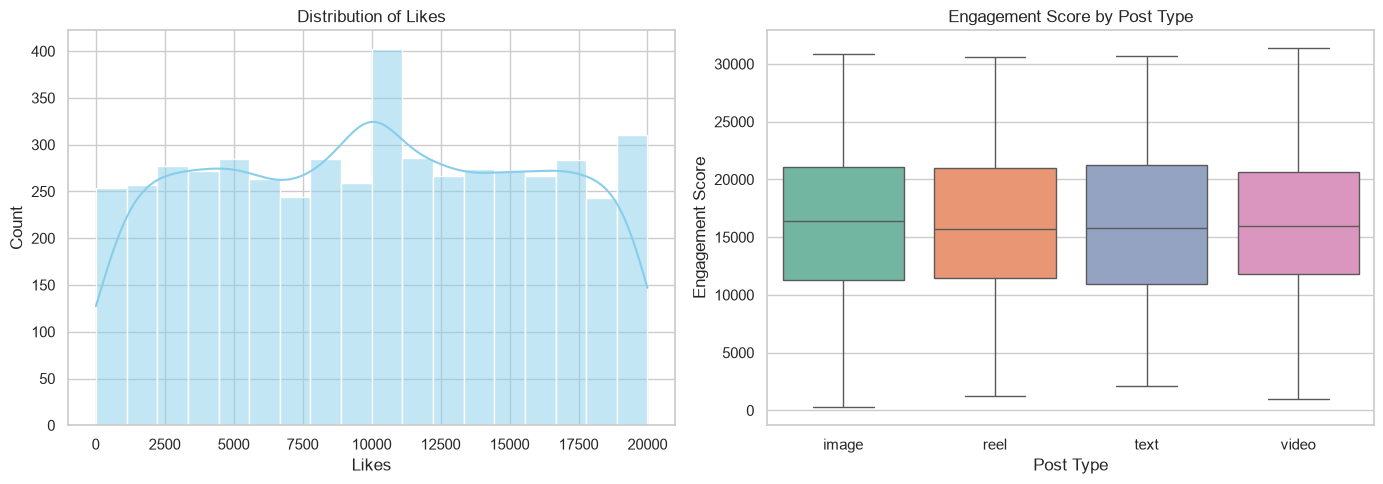

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['likes'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Likes')
axes[0].set_xlabel('Likes')
axes[0].set_ylabel('Count')

sns.boxplot(x='post_type', y='engagement_score', data=df, ax=axes[1], palette='Set2')
axes[1].set_title('Engagement Score by Post Type')
axes[1].set_xlabel('Post Type')
axes[1].set_ylabel('Engagement Score')

plt.tight_layout()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_4508\279130961.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='country', y='engagement_score', data=avg_eng_country, ax=axes[0], palette='viridis')


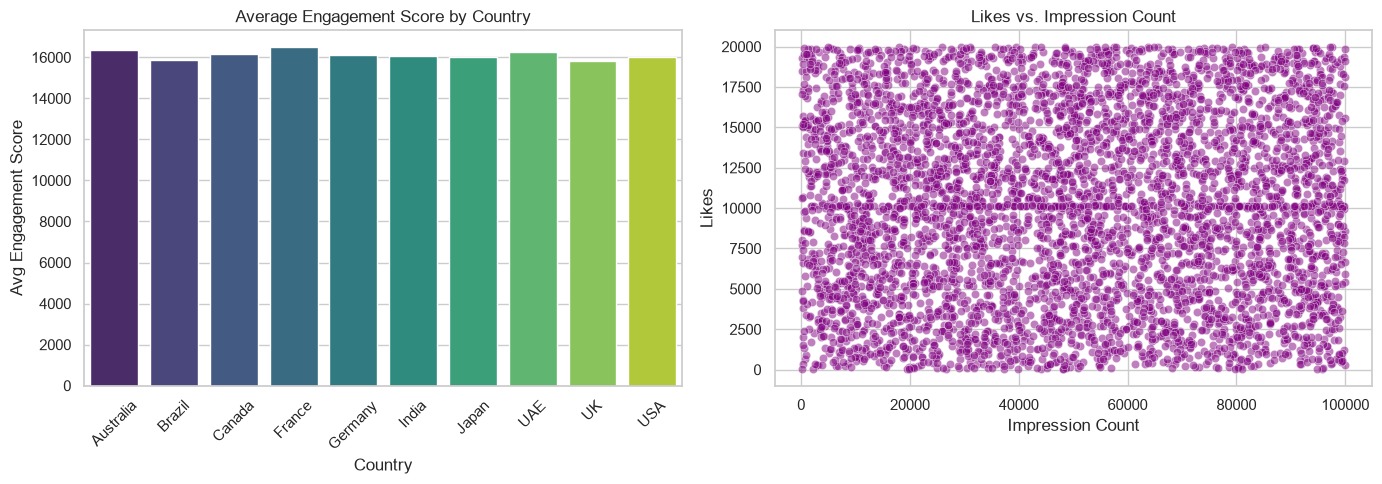

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

avg_eng_country = df.groupby('country')['engagement_score'].mean().reset_index()
sns.barplot(x='country', y='engagement_score', data=avg_eng_country, ax=axes[0], palette='viridis')
axes[0].set_title('Average Engagement Score by Country')
axes[0].set_xlabel('Country')
axes[0].set_ylabel('Avg Engagement Score')
axes[0].tick_params(axis='x', rotation=45)

sns.scatterplot(x='impression_count', y='likes', data=df, ax=axes[1], alpha=0.5, color='purple')
axes[1].set_title('Likes vs. Impression Count')
axes[1].set_xlabel('Impression Count')
axes[1].set_ylabel('Likes')

plt.tight_layout()
plt.show()

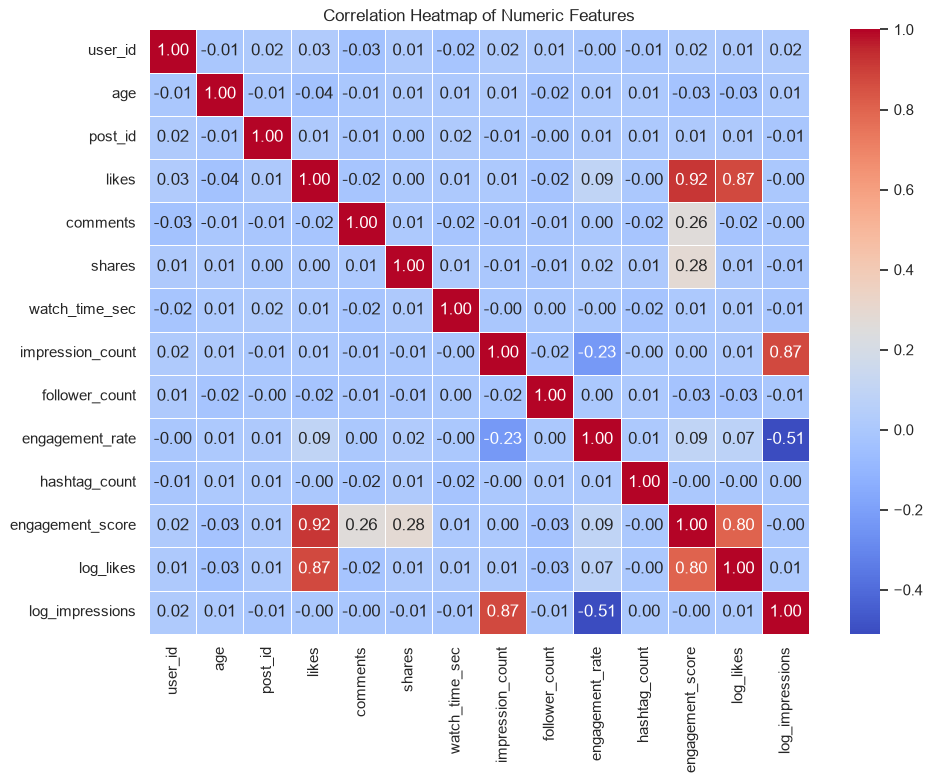

In [47]:
plt.figure(figsize=(10, 8))
numeric_cols = df.select_dtypes(include=['int64', 'float64'])
sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Numeric Features')
plt.tight_layout()
plt.show()

In [48]:
df.to_csv('social_media_engagement_cleaned.csv', index=False)

print("Dataset successfully exported as 'social_media_engagement_cleaned.csv'!")

Dataset successfully exported as 'social_media_engagement_cleaned.csv'!


In [49]:
stats_cols = ['likes', 'comments', 'shares', 'watch_time_sec', 'engagement_rate', 'follower_count']

stats_df = pd.DataFrame({
    'Mean': df[stats_cols].mean(),
    'Median': df[stats_cols].median(),
    'Mode': df[stats_cols].mode().iloc[0],
    'Std Dev': df[stats_cols].std(),
    'Variance': df[stats_cols].var(),
    '25th Percentile': df[stats_cols].quantile(0.25),
    '50th Percentile': df[stats_cols].quantile(0.50),
    '75th Percentile': df[stats_cols].quantile(0.75),
    'Skewness': df[stats_cols].skew(),
    'Kurtosis': df[stats_cols].kurt()
})

display(stats_df)

,Mean,Median,Mode,Std Dev,Variance,25th Percentile,50th Percentile,75th Percentile,Skewness,Kurtosis
likes,10106.997400,10105.500000,10105.500000,5702.293017,3.251615e+07,5235.000000,10105.500000,14959.000000,-0.006894,-1.149992
comments,1502.039800,1497.000000,1497.000000,856.393312,7.334095e+05,792.000000,1497.000000,2235.250000,0.003802,-1.144375
shares,1002.910600,1012.000000,1012.000000,570.855200,3.258757e+05,511.000000,1012.000000,1483.000000,-0.014654,-1.146857
watch_time_sec,4014.503200,4034.500000,916.000000,2308.096459,5.327309e+06,2017.750000,4034.500000,6020.250000,-0.018196,-1.195652
engagement_rate,0.964356,0.253896,0.006363,5.318029,2.828143e+01,0.145781,0.253896,0.504794,18.781271,482.991739
follower_count,393698.224800,388982.000000,497502.000000,230927.884535,5.332769e+10,194480.000000,388982.000000,589744.250000,0.041118,-1.189474


C:\Users\HP\AppData\Local\Temp\ipykernel_4508\1278365832.py:36: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[2, 1].boxplot(df['engagement_rate'].dropna(), vert=False, patch_artist=True, boxprops=dict(facecolor='lightgreen'))


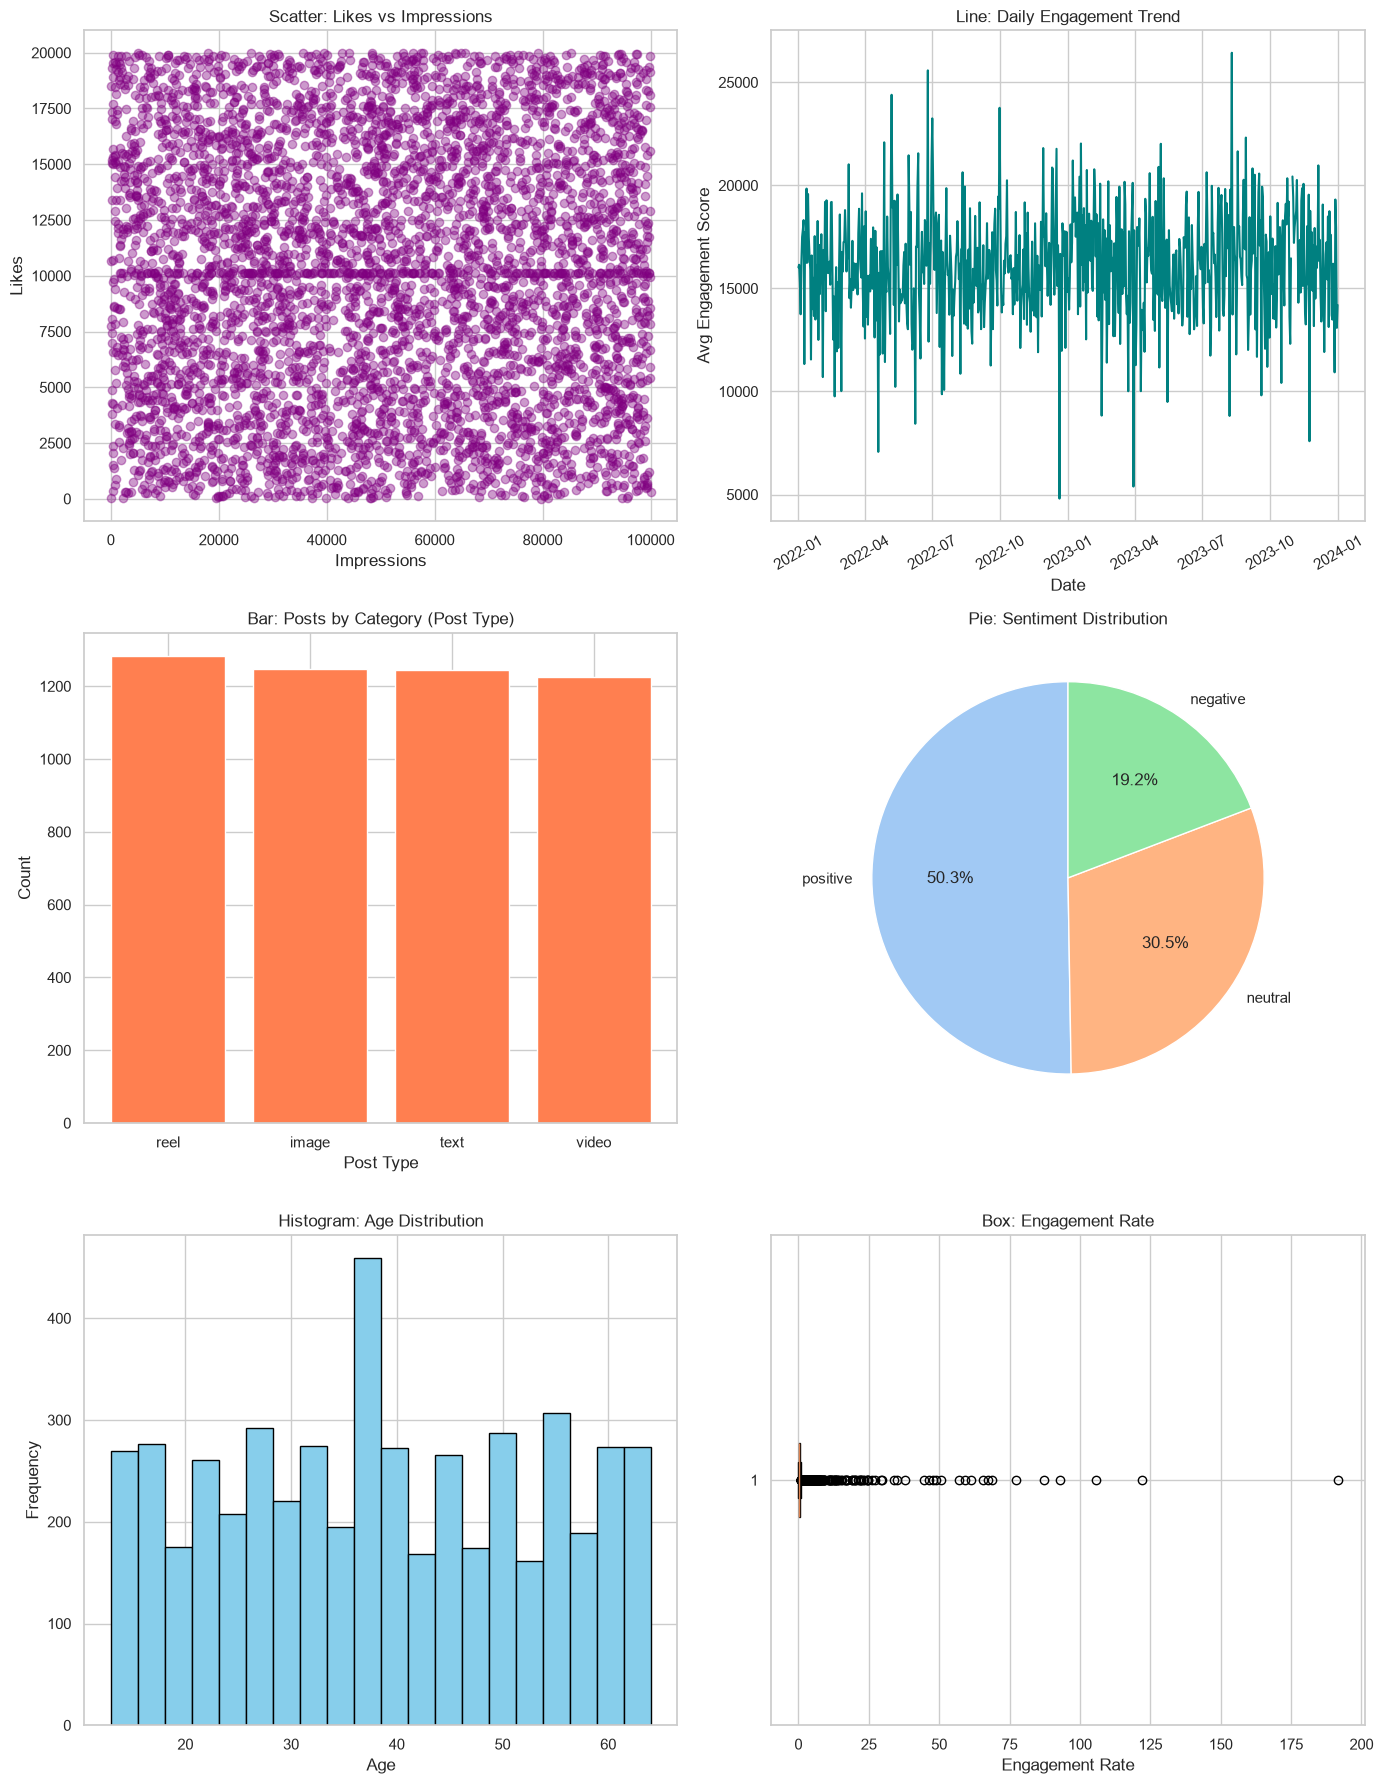

In [51]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df['posted_at'] = pd.to_datetime(df['posted_at'])

fig, axes = plt.subplots(3, 2, figsize=(14, 18))

axes[0, 0].scatter(df['impression_count'], df['likes'], alpha=0.4, color='purple')
axes[0, 0].set_title('Scatter: Likes vs Impressions')
axes[0, 0].set_xlabel('Impressions')
axes[0, 0].set_ylabel('Likes')

daily_trend = df.set_index('posted_at').resample('D')['engagement_score'].mean()
axes[0, 1].plot(daily_trend.index, daily_trend.values, color='teal', linewidth=1.5)
axes[0, 1].set_title('Line: Daily Engagement Trend')
axes[0, 1].set_xlabel('Date')
axes[0, 1].set_ylabel('Avg Engagement Score')
axes[0, 1].tick_params(axis='x', rotation=30)

post_counts = df['post_type'].value_counts()
axes[1, 0].bar(post_counts.index, post_counts.values, color='coral')
axes[1, 0].set_title('Bar: Posts by Category (Post Type)')
axes[1, 0].set_xlabel('Post Type')
axes[1, 0].set_ylabel('Count')

sentiment_counts = df['sentiment'].value_counts()
axes[1, 1].pie(sentiment_counts.values, labels=sentiment_counts.index, autopct='%1.1f%%', startangle=90, colors=sns.color_palette('pastel'))
axes[1, 1].set_title('Pie: Sentiment Distribution')

axes[2, 0].hist(df['age'].dropna(), bins=20, color='skyblue', edgecolor='black')
axes[2, 0].set_title('Histogram: Age Distribution')
axes[2, 0].set_xlabel('Age')
axes[2, 0].set_ylabel('Frequency')

axes[2, 1].boxplot(df['engagement_rate'].dropna(), vert=False, patch_artist=True, boxprops=dict(facecolor='lightgreen'))
axes[2, 1].set_title('Box: Engagement Rate')
axes[2, 1].set_xlabel('Engagement Rate')

plt.tight_layout()
plt.show()